# 03 · LangChain and LlamaIndex

Modules 01 and 02 built retrieval by hand, which is the best way to understand it. In practice most teams
reach for a **framework** that packages the usual pieces (document objects, splitters, vector stores,
retrievers, chains). Two dominate: **LangChain**, a general toolkit for composing LLM applications, and
**LlamaIndex**, centred on indexing and querying your own data. This module runs the *same* corpus, the
*same* embedding model and the *same* questions through both, next to our own few lines of NumPy, and
measures what you actually gain and pay.

In real projects of this portfolio, a wind-farm analytics agent used **LangChain with FAISS** over free-text
incident logs and **LlamaIndex** over structured turbine specifications, as two independent retrieval stacks
behind one agent. The comparison below is why that is a reasonable choice, and also why it is not the only one.

**You will learn**
1. The vocabulary both frameworks share: document, node/chunk, embedding, vector store, retriever, chain
2. A LangChain pipeline: `Document`, splitter, FAISS store, retriever and an LCEL chain
3. A LlamaIndex pipeline: `Document`, node parser, `VectorStoreIndex`, retriever and query engine
4. A fair comparison: lines of code, retrieval quality, import time and install size, all measured
5. What each framework abstracts away, and when to skip both

## 1. The same ingredients for all three

To compare frameworks fairly, everything that is not the framework must be identical. We use the
Harbourview handbook, the questions of module 02 (14 original and 10 paraphrases, defined inline here) and
the **same embedding model**, `all-MiniLM-L6-v2`, wrapped once for each framework. If retrieval results
differ, the difference comes from the framework, not from the model.

### Picture: the same five ingredients in three wrappers

Every retrieval pipeline needs the same pieces. The columns are the pieces, the rows are who provides them.
The vocabulary changes from row to row; the idea does not, and that is why the three give the same retrieval
once the embedding model is held fixed.

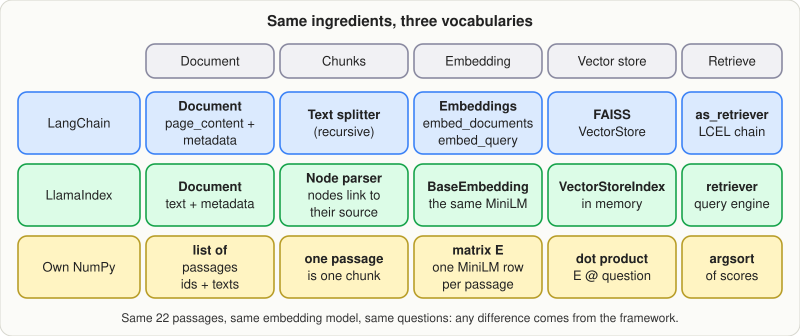

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(800, 336, [
    ("box", 146, 44, 128, 34, "Document", "grey"),
    ("box", 280, 44, 128, 34, "Chunks", "grey"),
    ("box", 414, 44, 128, 34, "Embedding", "grey"),
    ("box", 548, 44, 128, 34, "Vector store", "grey"),
    ("box", 682, 44, 100, 34, "Retrieve", "grey"),
    ("box", 18, 92, 122, 62, "LangChain", "blue"),
    ("box", 146, 92, 128, 62, "Document\npage_content +\nmetadata", "blue"),
    ("box", 280, 92, 128, 62, "Text splitter\n(recursive)", "blue"),
    ("box", 414, 92, 128, 62, "Embeddings\nembed_documents\nembed_query", "blue"),
    ("box", 548, 92, 128, 62, "FAISS\nVectorStore", "blue"),
    ("box", 682, 92, 100, 62, "as_retriever\nLCEL chain", "blue"),
    ("box", 18, 164, 122, 62, "LlamaIndex", "green"),
    ("box", 146, 164, 128, 62, "Document\ntext + metadata", "green"),
    ("box", 280, 164, 128, 62, "Node parser\nnodes link to\ntheir source", "green"),
    ("box", 414, 164, 128, 62, "BaseEmbedding\nthe same MiniLM", "green"),
    ("box", 548, 164, 128, 62, "VectorStoreIndex\nin memory", "green"),
    ("box", 682, 164, 100, 62, "retriever\nquery engine", "green"),
    ("box", 18, 236, 122, 62, "Own NumPy", "gold"),
    ("box", 146, 236, 128, 62, "list of\npassages\nids + texts", "gold"),
    ("box", 280, 236, 128, 62, "one passage\nis one chunk", "gold"),
    ("box", 414, 236, 128, 62, "matrix E\none MiniLM row\nper passage", "gold"),
    ("box", 548, 236, 128, 62, "dot product\nE @ question", "gold"),
    ("box", 682, 236, 100, 62, "argsort\nof scores", "gold"),
    ("text", 400, 322, "Same 22 passages, same embedding model, same questions: any difference comes from the framework.", 12, "middle"),
], "Same ingredients, three vocabularies")

In [2]:
# The Harbourview handbook: 22 passages, fictional, written for this course
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, question, gold passage, fact the answer must contain); None = the handbook does not say
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [3]:
import re, time, math, inspect, subprocess, sys, warnings
import numpy as np
warnings.filterwarnings("ignore")

PARAPHRASES = [
    ("r01", "Are boats cancelled when the sea is too rough?", "p02"),
    ("r02", "Can I go up the tower alone to fix something?", "p03"),
    ("r03", "How big are the blades?", "p04"),
    ("r04", "Who do I call in the middle of the night about an accident?", "p18"),
    ("r05", "What if the oil in the gearbox gets dirty?", "p07"),
    ("r06", "Do you stop work when whales or seals swim close?", "p13"),
    ("r07", "How much spare equipment is kept on shore?", "p16"),
    ("r08", "Is the farm allowed to produce at full output?", "p21"),
    ("r09", "What should new colleagues do before their first trip?", "p22"),
    ("r10", "How should rubbish and old oil be handled?", "p15"),
]
BATTERY = [(q[0], q[1], q[2]) for q in QUESTIONS if q[2]] + PARAPHRASES      # 24 questions, all answerable
ids = [p[0] for p in PASSAGES]
texts = [f"{section}. {text}" for _, section, text in PASSAGES]
print(len(PASSAGES), "passages,", len(BATTERY), "questions with a known gold passage")

from sentence_transformers import SentenceTransformer
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")

def evaluate(search):
    # search(question) -> list of passage ids, best first. Returns hit@1, hit@3, MRR over the battery
    ranks = []
    for _, question, gold in BATTERY:
        order = search(question)
        ranks.append(order.index(gold) + 1 if gold in order else len(ids) + 1)
    r = np.array(ranks)
    return dict(hit1=float((r == 1).mean()), hit3=float((r <= 3).mean()), mrr=float((1 / r).mean()))

22 passages, 24 questions with a known gold passage


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3481.14it/s]

## 2. Our own retriever (the baseline to beat)

Module 02 in a dozen lines: embed the passages once, embed the question, rank by dot product. Any framework
has to justify itself against this.

In [4]:
def build_own():
    E = minilm.encode(texts, normalize_embeddings=True)
    def search(question, k=len(ids)):
        scores = E @ minilm.encode(question, normalize_embeddings=True)
        return [ids[i] for i in np.argsort(-scores)[:k]]
    return search

t0 = time.perf_counter(); own = build_own(); t_own = time.perf_counter() - t0
print(f"built in {t_own:.2f} s")
print(own("What wave height stops the crew boats from sailing?", k=3))

built in 0.50 s
['p02', 'p13', 'p15']


## 3. LangChain

LangChain's core idea is a set of small interfaces (`Document`, `Embeddings`, `VectorStore`, `Retriever`,
`Runnable`) so that components can be swapped: change one line and FAISS becomes pgvector, or a local model
becomes a hosted one. The pipeline below uses:

* **`Document`**: text plus a `metadata` dict (here the passage id and section), which travels with every
  chunk and comes back with every hit, so a citation is free.
* **A text splitter**: `RecursiveCharacterTextSplitter` cuts long text on paragraph, then sentence, then
  word boundaries. Our passages are already short, so it should leave them alone; we check that.
* **`Embeddings`**: an interface with `embed_documents` and `embed_query`. We wrap our MiniLM model once.
* **FAISS** (Facebook AI Similarity Search): the vector index from module 02, behind LangChain's
  `VectorStore` interface.
* **A retriever**: `vectorstore.as_retriever()`, which returns `Document`s for a question.

In [5]:
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS

class MiniLMEmbeddings(Embeddings):
    def embed_documents(self, texts):
        return minilm.encode(texts, normalize_embeddings=True).tolist()
    def embed_query(self, text):
        return minilm.encode(text, normalize_embeddings=True).tolist()

def build_langchain(k=len(ids)):
    docs = [Document(page_content=t, metadata={"id": i, "section": s}) for (i, s, _), t in zip(PASSAGES, texts)]
    chunks = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=0).split_documents(docs)
    store = FAISS.from_documents(chunks, MiniLMEmbeddings())
    retriever = store.as_retriever(search_kwargs={"k": k})
    return (lambda question: [d.metadata["id"] for d in retriever.invoke(question)]), docs, chunks, retriever

t0 = time.perf_counter(); lc_search, lc_docs, lc_chunks, lc_retriever = build_langchain(); t_lc = time.perf_counter() - t0
print(f"built in {t_lc:.2f} s; {len(lc_docs)} documents -> {len(lc_chunks)} chunks (the splitter left every passage whole: {len(lc_docs) == len(lc_chunks)})")
hit = lc_retriever.invoke("What wave height stops the crew boats from sailing?")[0]
print("top hit:", hit.metadata, "|", hit.page_content[:70], "...")

built in 0.62 s; 22 documents -> 22 chunks (the splitter left every passage whole: True)
top hit: {'id': 'p02', 'section': 'Safety / Weather limits'} | Safety / Weather limits. Crew transfer vessels do not sail when the si ...


### A chain with the pipe operator (LCEL)

LangChain's expression language composes steps with `|`: retrieve, format a prompt, call a model, parse the
output. Here the "model" is a local, deterministic stand-in (the extractive generator of module 01), wrapped in
`RunnableLambda` so it fits in the chain. Replace it with a hosted chat model (module 04) and nothing else
changes; that is the point of the interface.

In [6]:
from langchain_core.runnables import RunnableLambda, RunnablePassthrough

STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def toks(s): return {w for w in re.findall(r"[a-z0-9]+", s.lower()) if w not in STOP}

def format_context(docs):
    return "\n".join(f"[{n}] ({d.metadata['id']}) {d.page_content}" for n, d in enumerate(docs, start=1))

def standin_generator(inputs):
    # picks the sentence of the best passage that shares most words with the question, and cites it [1]
    question, docs = inputs["question"], inputs["docs"]
    body = docs[0].page_content.split(". ", 1)[1]
    best = max(re.split(r"(?<=[.!?])\s+", body), key=lambda s: len(toks(question) & toks(s)))
    return f"{best} [1] (source: {docs[0].metadata['section']})"

# the retriever above returns every passage; the chain keeps the top 3
chain = (
    {"question": RunnablePassthrough(), "docs": lc_retriever | RunnableLambda(lambda ds: ds[:3])}
    | RunnableLambda(standin_generator)
)
print(chain.invoke("What qualification do I need before getting on the boat?"))
print(chain.invoke("How soon must an injury be reported?"))
print("\nthe chain is a", type(chain).__name__, "with", len(chain.steps), "steps:", [type(x).__name__ for x in chain.steps])

Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. [1] (source: Safety / Weather limits)
Any injury or near miss is reported within one hour and a written report is filed within 24 hours. [1] (source: Reporting / Incidents)

the chain is a RunnableSequence with 2 steps: ['RunnableParallel', 'RunnableLambda']


Look at the first answer: the question was about the *qualification* needed to board, and the chain answered
with the weather limits. It is one of the two battery questions where the top retrieved passage is not the
gold one (see the hit@1 below), and the chain faithfully answers from what it was given. A framework wires
the steps together; it does not make a weak retrieval strong.

## 4. LlamaIndex

LlamaIndex starts from the data rather than the chain. You hand it documents and it builds an **index**
(here a `VectorStoreIndex`) that you then query. Its vocabulary:

* **`Document`** becomes **nodes** (the chunks) through a *node parser*; nodes keep a link to their source.
* **`VectorStoreIndex`** embeds the nodes and stores the vectors (in memory by default).
* **A retriever** returns *scored* nodes, and a **query engine** adds the answer-synthesis step (retrieve,
  build a prompt, call the LLM). We give it a `MockLLM` so nothing leaves the machine, and read the retrieved
  nodes, which is where retrieval quality lives.

In [7]:
from llama_index.core import VectorStoreIndex, Document as LIDocument
from llama_index.core.embeddings import BaseEmbedding
from llama_index.core.llms import MockLLM
from llama_index.core.node_parser import SentenceSplitter

class MiniLMLlama(BaseEmbedding):
    def _get_query_embedding(self, query): return minilm.encode(query, normalize_embeddings=True).tolist()
    def _get_text_embedding(self, text): return minilm.encode(text, normalize_embeddings=True).tolist()
    async def _aget_query_embedding(self, query): return self._get_query_embedding(query)
    async def _aget_text_embedding(self, text): return self._get_text_embedding(text)

def build_llamaindex(k=len(ids)):
    docs = [LIDocument(text=t, metadata={"id": i, "section": s}) for (i, s, _), t in zip(PASSAGES, texts)]
    index = VectorStoreIndex.from_documents(docs, embed_model=MiniLMLlama(model_name="minilm"),
                                            transformations=[SentenceSplitter(chunk_size=512, chunk_overlap=0)], show_progress=False)
    retriever = index.as_retriever(similarity_top_k=k)
    return (lambda question: [n.node.metadata["id"] for n in retriever.retrieve(question)]), index, retriever

t0 = time.perf_counter(); li_search, li_index, li_retriever = build_llamaindex(); t_li = time.perf_counter() - t0
print(f"built in {t_li:.2f} s; {len(li_index.docstore.docs)} nodes in the index")
hit = li_retriever.retrieve("What wave height stops the crew boats from sailing?")[0]
print(f"top hit: score {hit.score:.2f}", hit.node.metadata, "|", hit.node.get_content()[:60], "...")

engine = li_index.as_query_engine(llm=MockLLM(), embed_model=MiniLMLlama(model_name="minilm"), similarity_top_k=3)
response = engine.query("How soon must an injury be reported?")
print("\nquery engine sources:", [(n.node.metadata["id"], round(n.score, 2)) for n in response.source_nodes])
print("response object:", type(response).__name__, "(the text is the MockLLM's placeholder, by design)")

built in 1.27 s; 22 nodes in the index
top hit: score 0.62 {'id': 'p02', 'section': 'Safety / Weather limits'} | Safety / Weather limits. Crew transfer vessels do not sail w ...

query engine sources: [('p19', 0.52), ('p08', 0.31), ('p18', 0.26)]
response object: Response (the text is the MockLLM's placeholder, by design)


## 5. Comparing them honestly

Three measurements: whether retrieval differs, how much code each pipeline takes, and what each costs to
load. Retrieval first, on the 24-question battery.

### Picture: what flows through the three pipelines

The same inputs go through each pipeline, and each one is asked the same 24 battery questions. The right-hand
boxes are the measured results printed by the next cell. The note explains the one place where they differ.

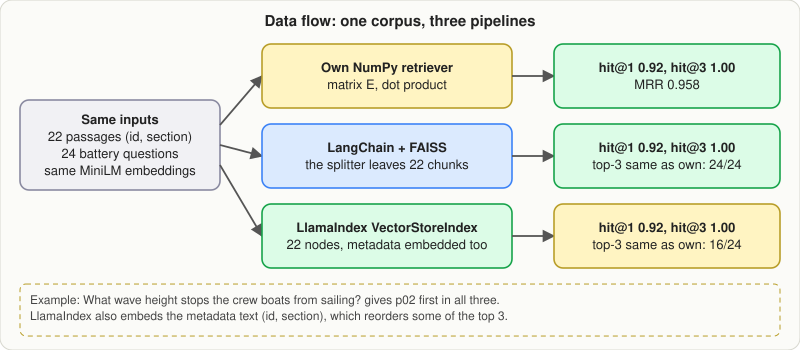

In [8]:
diagram(800, 350, [
    ("box", 20, 100, 200, 90, "Same inputs\n22 passages (id, section)\n24 battery questions\nsame MiniLM embeddings", "grey"),
    ("arrow", 220, 125, 262, 76, ""),
    ("arrow", 220, 145, 262, 156, ""),
    ("arrow", 220, 165, 262, 236, ""),
    ("box", 262, 44, 250, 64, "Own NumPy retriever\nmatrix E, dot product", "gold"),
    ("box", 262, 124, 250, 64, "LangChain + FAISS\nthe splitter leaves 22 chunks", "blue"),
    ("box", 262, 204, 250, 64, "LlamaIndex VectorStoreIndex\n22 nodes, metadata embedded too", "green"),
    ("arrow", 512, 76, 554, 76, ""),
    ("arrow", 512, 156, 554, 156, ""),
    ("arrow", 512, 236, 554, 236, ""),
    ("box", 554, 44, 226, 64, "hit@1 0.92, hit@3 1.00\nMRR 0.958", "green"),
    ("box", 554, 124, 226, 64, "hit@1 0.92, hit@3 1.00\ntop-3 same as own: 24/24", "green"),
    ("box", 554, 204, 226, 64, "hit@1 0.92, hit@3 1.00\ntop-3 same as own: 16/24", "gold"),
    ("note", 20, 284, 760, 52, "Example: What wave height stops the crew boats from sailing? gives p02 first in all three.\nLlamaIndex also embeds the metadata text (id, section), which reorders some of the top 3."),
], "Data flow: one corpus, three pipelines")

In [9]:
def row(name, search):
    m = evaluate(search)
    print(f"{name:34s} hit@1 {m['hit1']:.2f}   hit@3 {m['hit3']:.2f}   MRR {m['mrr']:.3f}")
    return m

m_own = row("own NumPy retriever", own)
m_lc = row("LangChain + FAISS", lc_search)
m_li = row("LlamaIndex VectorStoreIndex", li_search)
qs = [q for _, q, _ in BATTERY]
agree = lambda a, b, k: sum(a(q)[:k] == b(q)[:k] for q in qs)
print(f"\nsame top-1 on {agree(own, lc_search, 1)}/{len(qs)} questions (own vs LangChain) and {agree(own, li_search, 1)}/{len(qs)} (own vs LlamaIndex)")
print(f"same ordered top-3: own vs LangChain {agree(own, lc_search, 3)}/{len(qs)}, own vs LlamaIndex {agree(own, li_search, 3)}/{len(qs)}")
from llama_index.core.schema import MetadataMode
node = next(iter(li_index.docstore.docs.values()))
print("\ntext LlamaIndex embeds for one node by default:\n  ", repr(node.get_content(metadata_mode=MetadataMode.EMBED)[:110]))

own NumPy retriever                hit@1 0.92   hit@3 1.00   MRR 0.958


LangChain + FAISS                  hit@1 0.92   hit@3 1.00   MRR 0.958


LlamaIndex VectorStoreIndex        hit@1 0.92   hit@3 1.00   MRR 0.958



same top-1 on 24/24 questions (own vs LangChain) and 24/24 (own vs LlamaIndex)


same ordered top-3: own vs LangChain 24/24, own vs LlamaIndex 16/24

text LlamaIndex embeds for one node by default:
   'id: p01\nsection: Safety / Access\n\nSafety / Access. Technicians must hold a valid GWO Basic Safety Training cer'


In [10]:
loc = {name: len([l for l in inspect.getsource(fn).splitlines() if l.strip() and not l.strip().startswith("#")])
       for name, fn in [("own NumPy retriever", build_own), ("LangChain + FAISS", build_langchain), ("LlamaIndex", build_llamaindex)]}
def class_source(name):
    # classes defined in a notebook have no source file: read them back from the cell history instead
    cell = next(c for c in get_ipython().user_ns["_ih"] if f"class {name}(" in c)
    start = cell.index(f"class {name}(")
    block = cell[start:].split("\n")
    out = [block[0]]
    for line in block[1:]:
        if line.strip() and not line.startswith(" "):
            break
        out.append(line)
    return "\n".join(out)

extra = {"LangChain + FAISS": class_source("MiniLMEmbeddings"), "LlamaIndex": class_source("MiniLMLlama")}
print("non-blank, non-comment lines of the build function (+ the embedding adapter each framework needs):")
for name, n in loc.items():
    adapter = len([l for l in extra.get(name, "").splitlines() if l.strip()])
    print(f"  {name:22s}{n:4d}  + adapter {adapter:3d}")

def fresh_import_seconds(stmt):
    code_ = f"import time; t = time.perf_counter(); {stmt}; print(time.perf_counter() - t)"
    out = [float(subprocess.run([sys.executable, "-c", code_], capture_output=True, text=True).stdout.strip().splitlines()[-1]) for _ in range(2)]
    return min(out)

import importlib.metadata as md_
def installed_mb(*dists):
    total, seen = 0, set()
    for d in dists:
        try:
            for f in md_.files(d) or []:
                p = f.locate()
                if str(p) not in seen and p.exists():
                    seen.add(str(p)); total += p.stat().st_size
        except md_.PackageNotFoundError:
            pass
    return total / 1e6

print("\nimport time in a fresh interpreter (best of 2) and size of the framework's own packages:")
for label, stmt, dists in [
    ("numpy only", "import numpy", ["numpy"]),
    ("LangChain + FAISS", "from langchain_core.documents import Document; from langchain_community.vectorstores import FAISS; from langchain_text_splitters import RecursiveCharacterTextSplitter", ["langchain-core", "langchain-community", "langchain-text-splitters", "faiss-cpu"]),
    ("LlamaIndex", "from llama_index.core import VectorStoreIndex", ["llama-index-core"]),
]:
    print(f"  {label:20s}{fresh_import_seconds(stmt):6.2f} s import   {installed_mb(*dists):6.0f} MB installed")

non-blank, non-comment lines of the build function (+ the embedding adapter each framework needs):
  own NumPy retriever      6  + adapter   0
  LangChain + FAISS        6  + adapter   5
  LlamaIndex               6  + adapter   5

import time in a fresh interpreter (best of 2) and size of the framework's own packages:


  numpy only            0.16 s import       65 MB installed


  LangChain + FAISS     1.42 s import       94 MB installed


  LlamaIndex            2.40 s import       27 MB installed


Read the three results together:

* **Retrieval quality is a property of the embedding model and the chunking, not of the framework.** The
  three retrievers get identical hit@1, hit@3 and MRR. Our NumPy retriever and LangChain+FAISS return the
  same ordered top three on every question. LlamaIndex agrees on the top result everywhere but orders the
  2nd and 3rd differently on some questions, and the last printed line shows why: **by default it embeds the
  node's metadata (`id`, `section`) together with the text**, so the vector it searches is not the vector
  you built. That is a framework default silently changing your retrieval, which you only notice because you
  compared against a baseline. (Exercise 3 aligns the two.) Choosing one framework over the other will not
  make answers better or worse; module 07 shows what does.
* **At this scale the frameworks cost weight and an adapter, not lines.** The build functions are the same
  length (about six lines each) and each framework also needs a five-line adapter to use our local model,
  which is where a hosted model would normally plug in. The real price is import time and installed size,
  measured above: far above NumPy's. On an always-on server with a small memory budget that matters (a point
  the production module returns to).
* **What you buy is interchangeability and ecosystem**: a hundred vector stores, loaders for PDFs and
  databases, callbacks for tracing (module 09), agents and graphs (module 05). If you need them, the cost is
  worth paying; if you need one retriever over one corpus, it is not.

## 6. What each framework abstracts, and when to skip both

| Concern | Our own code | LangChain | LlamaIndex |
|---|---|---|---|
| Unit of text | a string and an id | `Document` with `metadata` | `Document`, split into `Node`s that keep their source |
| Embedding | call the model | `Embeddings` interface | `BaseEmbedding` interface |
| Index | a NumPy matrix | any `VectorStore` (FAISS, pgvector, ...) | `VectorStoreIndex` over a pluggable store |
| Retrieval | `argsort` | `retriever.invoke` | `index.as_retriever`, with scored nodes |
| Composition | plain functions | `|` chains (LCEL), later LangGraph | query engines, routers, agents |
| Answer synthesis | your own prompt | a chain you assemble | built into the query engine |
| Strongest at | clarity, tiny footprint | wide integrations, composing steps | indexing structured and mixed data, built-in query patterns |

**When to skip both.** One corpus, one retriever, a few thousand chunks, a service that must stay small: the
dozen lines of NumPy in section 2 are easier to read, test and keep correct, and they import instantly. The
retrieval component of a small search endpoint in this portfolio is plain BM25 for exactly that reason. Reach
for a framework when you need what it brings (swappable stores, many loaders, tracing hooks, graphs of steps),
not by default; and do not mix two frameworks without a reason. The wind-farm agent above kept two stacks
because the two corpora were different in shape (free-text incident narratives versus structured specs) and
each framework suited one of them, and because the agent only ever sees both through a single `search`
function, so the choice stays local.

## Exercises

1. Change the splitter to `chunk_size=80` and rebuild the LangChain store. How many chunks do you get, and
   what happens to hit@1 and to the readability of a cited chunk?
2. Add a `k=2` retriever to the LCEL chain and print which passages the stand-in generator sees for the
   paraphrase questions. Where does it fail, and is the fault in retrieval or in the generator?
3. Make LlamaIndex embed only the text: set `excluded_embed_metadata_keys=["id", "section"]` on each
   `Document` and rebuild. Does its ordered top three now match the other two on every question?
4. Write a fourth retriever: BM25 from module 01 behind the same `search(question)` function, and evaluate it
   with the same `evaluate`. Which of the four would you ship for this corpus, and why?